# Self-Attention を NumPy で 1 行ずつ計算する

**出典**　機械学習 4 分野の教科書 — 第 8 章 2-C Transformer と生成モデル ／ 02 Self-Attention の数理

**このノートのパス**　`ml-code/08_transformer/02_self_attention_numpy.ipynb`

**このノートで確かめること**
本文の式 `softmax(QKᵀ / √d_k) V` を NumPy で書き、次の 4 点を数値で確かめる。

1. 各行の重みが合計 1 になり、出力が `V` の加重平均になっていること
2. PyTorch の `scaled_dot_product_attention` と一致すること
3. `√d_k` で割らないと、次元が大きいときに softmax が尖る（ほぼ 1 語しか見なくなる）こと
4. パディングマスクで、詰め物への重みがちょうど 0 になること

| 項目 | 内容 |
|---|---|
| 必要なパッケージ | `numpy`, `matplotlib`（② だけ `torch`） |
| 実行時間の目安 | 約 5 秒 |
| 前提 | **このノート単体で完結する**（他のノートを先に実行する必要はない） |

In [1]:
# 未導入なら実行する（Colab など）
# !pip install -q numpy matplotlib torch

## ① 式をそのまま書く

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def softmax(z, axis=-1):
    z = z - z.max(axis=axis, keepdims=True)      # 桁あふれ防止
    e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)

def self_attention(X, W_Q, W_K, W_V, mask=None, scale=True):
    Q, K, V = X @ W_Q, X @ W_K, X @ W_V          # Q = XW_Q, K = XW_K, V = XW_V
    d_k = Q.shape[-1]
    scores = Q @ K.T                             # n × n の類似度表
    if scale:
        scores = scores / np.sqrt(d_k)
    if mask is not None:                         # True の列（詰め物）は注目させない
        scores = np.where(mask[None, :], -np.inf, scores)
    A = softmax(scores)                          # 行ごとに合計 1
    return A @ V, A                              # 重みで V を加重平均

rng = np.random.default_rng(0)
n, d_model, d_k = 5, 16, 8                       # 5 語、埋め込み 16 次元、ヘッド 8 次元
X = rng.normal(size=(n, d_model))
W_Q, W_K, W_V = (rng.normal(scale=d_model**-0.5, size=(d_model, d_k)) for _ in range(3))

out, A = self_attention(X, W_Q, W_K, W_V)
print("X:", X.shape, " Q/K/V:", (X @ W_Q).shape, " 重み A:", A.shape, " 出力:", out.shape)
print("A の各行の合計:", A.sum(axis=1).round(6))
print("A（行＝注目する語、列＝注目される語）:")
print(A.round(3))

V = X @ W_V
print("出力 1 行目 = Σ A[0, j] · V[j] か:", np.allclose(out[0], (A[0][:, None] * V).sum(0)))

X: (5, 16)  Q/K/V: (5, 8)  重み A: (5, 5)  出力: (5, 8)
A の各行の合計: [1. 1. 1. 1. 1.]
A（行＝注目する語、列＝注目される語）:
[[0.113 0.29  0.044 0.285 0.268]
 [0.05  0.211 0.23  0.032 0.476]
 [0.181 0.033 0.609 0.15  0.028]
 [0.107 0.266 0.071 0.101 0.455]
 [0.084 0.023 0.654 0.231 0.008]]
出力 1 行目 = Σ A[0, j] · V[j] か: True


## ② PyTorch の実装と一致するか

PyTorch 2.x の `F.scaled_dot_product_attention` は、FlashAttention などの高速版を内部で選ぶ関数である。
計算の中身は上の 1 行と同じはずなので、同じ `Q, K, V` を渡して比べる。

In [3]:
import torch
import torch.nn.functional as F

Q, K, V = (torch.tensor(X @ W) for W in (W_Q, W_K, W_V))
out_torch = F.scaled_dot_product_attention(Q[None], K[None], V[None])[0].numpy()
print(f"NumPy vs PyTorch  最大絶対差: {np.abs(out - out_torch).max():.2e}")

NumPy vs PyTorch  最大絶対差: 4.44e-16


## ③ なぜ √d_k で割るのか

`q` と `k` の各成分が平均 0・分散 1 なら、内積 `q·k` の分散は `d_k` になる。
つまり**次元を増やすほどスコアの振れ幅が大きくなり、softmax が 1 か所に張り付く**。
ランダムな `Q, K` で、d_k を変えながら「各行の最大の重み」の平均を測る。

In [4]:
n = 16
print(f"{'d_k':>5} | {'スコアの標準偏差':>10} | {'最大重み（割らない）':>12} | {'最大重み（√d_k で割る）':>14}")
for d in [4, 16, 64, 256, 1024]:
    Qr, Kr = rng.normal(size=(n, d)), rng.normal(size=(n, d))
    s = Qr @ Kr.T
    print(f"{d:>5} | {s.std():>17.1f} | {softmax(s).max(1).mean():>21.3f} |"
          f" {softmax(s / np.sqrt(d)).max(1).mean():>24.3f}")
print(f"参考：{n} 語に均等に注目したときの重み = {1/n:.3f}")

  d_k |   スコアの標準偏差 |   最大重み（割らない） | 最大重み（√d_k で割る）
    4 |               1.8 |                 0.323 |                    0.183
   16 |               4.0 |                 0.730 |                    0.241
   64 |               8.0 |                 0.814 |                    0.247
  256 |              15.9 |                 0.938 |                    0.255
 1024 |              32.3 |                 0.978 |                    0.262
参考：16 語に均等に注目したときの重み = 0.062


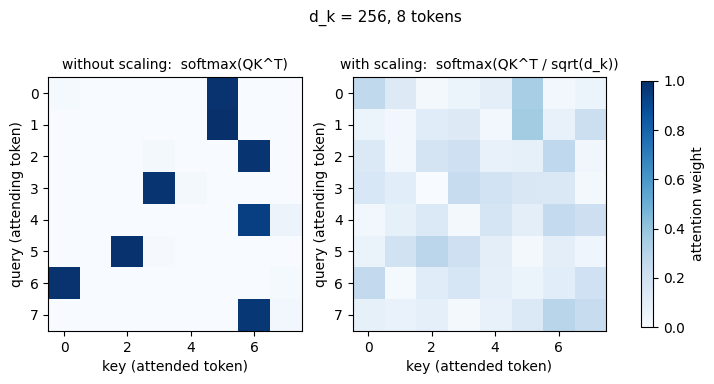

In [5]:
d = 256
Qr, Kr = rng.normal(size=(8, d)), rng.normal(size=(8, d))
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (title, s) in zip(axes, [("without scaling:  softmax(QK^T)", Qr @ Kr.T),
                                 ("with scaling:  softmax(QK^T / sqrt(d_k))", Qr @ Kr.T / np.sqrt(d))]):
    im = ax.imshow(softmax(s), vmin=0, vmax=1, cmap="Blues")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("key (attended token)"); ax.set_ylabel("query (attending token)")
fig.colorbar(im, ax=axes, shrink=0.8, label="attention weight")
fig.suptitle(f"d_k = {d}, 8 tokens", fontsize=11)
plt.show()

## ④ パディングマスク

5 語のうち後ろ 2 語が詰め物（パディング）だとする。スコアを `-∞` にしてから softmax を取ると、その列の重みはちょうど 0 になる。

In [6]:
pad = np.array([False, False, False, True, True])      # 後ろ 2 語が詰め物
_, A_masked = self_attention(X, W_Q, W_K, W_V, mask=pad)
print("マスクあり A:")
print(A_masked.round(3))
print("詰め物の列への重みの最大値:", A_masked[:, pad].max())
print("各行の合計:", A_masked.sum(axis=1).round(6))

マスクあり A:
[[0.252 0.649 0.099 0.    0.   ]
 [0.102 0.43  0.468 0.    0.   ]
 [0.22  0.04  0.74  0.    0.   ]
 [0.241 0.6   0.159 0.    0.   ]
 [0.11  0.03  0.86  0.    0.   ]]
詰め物の列への重みの最大値: 0.0
各行の合計: [1. 1. 1. 1. 1.]


## ⑤ O(n²) のメモリ

Attention 重み行列は `n × n`。float32（4 バイト）で 1 ヘッド・1 層ぶんだけでもこうなる。

In [7]:
for n_tok in [512, 4_096, 32_768, 131_072]:
    mb = n_tok**2 * 4 / 1024**2
    print(f"系列長 {n_tok:>7,} 語 → 重み行列 {mb:>10,.0f} MB")

系列長     512 語 → 重み行列          1 MB
系列長   4,096 語 → 重み行列         64 MB
系列長  32,768 語 → 重み行列      4,096 MB
系列長 131,072 語 → 重み行列     65,536 MB


## 読み取りどころ

- **Self-Attention は「行列積 → softmax → 行列積」の 3 手だけ**。PyTorch の高速実装も、数式としてはこの 1 行と同じ結果を返す。
- **√d_k は飾りではない。**割らないと d_k = 256 では各行がほぼ 1 語にしか注目せず（最大重みが 1 に近い）、softmax の勾配がほぼ 0 になる。割ると、最大重みは d_k によらずほぼ一定に保たれる。
- **パディングマスクは「重みを小さくする」のではなく「ちょうど 0 にする」。**残りの語の重みで合計 1 に配り直される。
- **系列長を 8 倍にするとメモリは 64 倍**。長いコンテキストが難しい理由が、この 2 乗にある。